## ECON 372 - HW 3
## Renee Ngai

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Download the dataset 


In [3]:
hospital_panel = pd.read_csv(r"C:\Users\ngair\Downloads\hospital-panel.csv")

In [4]:
hospital_panel.head()

,provider_number,street,city,state,zip,beds,tot_discharges,price,year,hrr,mkt
0,10001,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301.0,425,16812.0,5298.301254,1998,2.0,11.0
1,10001,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301.0,400,17876.0,3903.631715,1999,2.0,11.0
2,10001,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301.0,353,17202.0,3902.972237,2000,2.0,11.0
3,10001,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301.0,353,19477.0,3211.728081,2001,2.0,11.0
4,10001,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301.0,353,19881.0,4255.351889,2002,2.0,11.0


## Q1 — Market definition and concentration (15 pts)


(3 points) Compute HHI three ways. Compute the HHI for each market and year under all three market definitions (zip, HRR, community-detection), and plot the average HHI over time for each definition. 



Year: 1998, HHI Zip: 0.9803, HHI HRR: 0.4238, HHI Community: 0.6006
Year: 1999, HHI Zip: 0.9729, HHI HRR: 0.2906, HHI Community: 0.5282
Year: 2000, HHI Zip: 0.9732, HHI HRR: 0.2978, HHI Community: 0.5232
Year: 2001, HHI Zip: 0.9734, HHI HRR: 0.2946, HHI Community: 0.5326
Year: 2002, HHI Zip: 0.9743, HHI HRR: 0.3018, HHI Community: 0.5340
Year: 2003, HHI Zip: 0.9752, HHI HRR: 0.3074, HHI Community: 0.5310
Year: 2004, HHI Zip: 0.9750, HHI HRR: 0.3060, HHI Community: 0.5426
Year: 2005, HHI Zip: 0.9724, HHI HRR: 0.3084, HHI Community: 0.5365
Year: 2006, HHI Zip: 0.9728, HHI HRR: 0.3065, HHI Community: 0.5415
Year: 2007, HHI Zip: 0.9728, HHI HRR: 0.3040, HHI Community: 0.5373
Year: 2008, HHI Zip: 0.9751, HHI HRR: 0.3115, HHI Community: 0.5393
Year: 2009, HHI Zip: 0.9756, HHI HRR: 0.3114, HHI Community: 0.5458
Year: 2010, HHI Zip: 0.9754, HHI HRR: 0.3190, HHI Community: 0.5533
Year: 2011, HHI Zip: 0.9749, HHI HRR: 0.3199, HHI Community: 0.5532
Year: 2012, HHI Zip: 0.9763, HHI HRR: 0.3232, HH

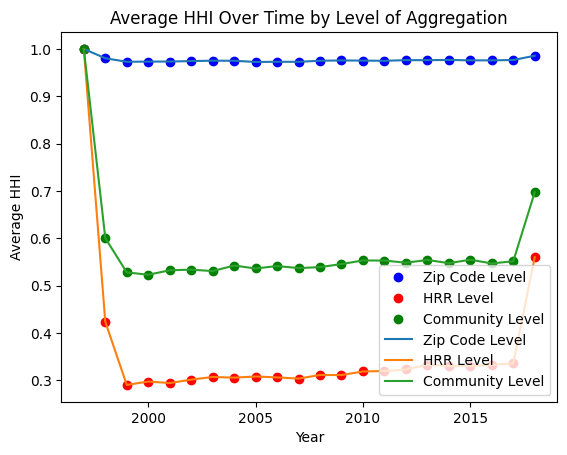

In [ ]:

for year in hospital_panel['year'].unique():
    HHI_zip_year = hospital_panel[hospital_panel['year'] == year].groupby('zip')['tot_discharges'].apply(lambda x: np.sum((x / x.sum()) ** 2)).mean()
    HHI_HRR_year = hospital_panel[hospital_panel['year'] == year].groupby('hrr')['tot_discharges'].apply(lambda x: np.sum((x / x.sum()) ** 2)).mean()
    HHI_community_year = hospital_panel[hospital_panel['year'] == year].groupby('mkt')['tot_discharges'].apply(lambda x: np.sum((x / x.sum()) ** 2)).mean()
    print(f"Year: {year}, HHI Zip: {HHI_zip_year:.4f}, HHI HRR: {HHI_HRR_year:.4f}, HHI Community: {HHI_community_year:.4f}")
    
    plt.plot(year, HHI_zip_year, 'bo', label='Zip Code Level' if year == hospital_panel['year'].unique()[0] else "")
    plt.plot(year, HHI_HRR_year, 'ro', label='HRR Level' if year == hospital_panel['year'].unique()[0] else "")
    plt.plot(year, HHI_community_year, 'go', label='Community Level' if year == hospital_panel['year'].unique()[0] else "")


HHI_zip_time = hospital_panel.groupby(['zip', 'year'])['tot_discharges'].apply(lambda x: np.sum((x / x.sum()) ** 2)).reset_index()
HHI_HRR_time = hospital_panel.groupby(['hrr', 'year'])['tot_discharges'].apply(lambda x: np.sum((x / x.sum()) ** 2)).reset_index()
HHI_community_time = hospital_panel.groupby(['mkt', 'year'])['tot_discharges'].apply(lambda x: np.sum((x / x.sum()) ** 2)).reset_index()

plt.plot(HHI_zip_time.groupby('year')['tot_discharges'].mean(), label='Zip Code Level')
plt.plot(HHI_HRR_time.groupby('year')['tot_discharges'].mean(), label='HRR Level')
plt.plot(HHI_community_time.groupby('year')['tot_discharges'].mean(), label='Community Level')
plt.title('Average HHI Over Time by Level of Aggregation')
plt.xlabel('Year')
plt.ylabel('Average HHI')
plt.legend()
plt.show()

(3 points) Why the definition matters. Explain why your assessment of how concentrated hospital markets are changes with the definition. Which definition is “correct,” and why is there no single right answer?



How concentrated hospital markets are changes becaus as discussed in class, what boundaries you draw for the market deteermines how competitors are counted and how large markets shares are. For example, for HHR HHI, ZIp code level HHI, and community level HHI all have  different market shares. No definitely is correct and there is no single right answer because a hospital might serve a really large market out of state as well so it is hard to define a right market share and definition matters in terms of merger and acquisitions and antitrust in hospitals.

(3 points) The problem with a simple average. Your part (a) averages HHI across markets. Single-hospital markets have HHI = 10,000, and a simple unweighted average gives each of them the same weight as a large market, so the many small markets raise the average. Show how weighting by discharges, or excluding single-hospital markets, changes the result, and what the plain average was leaving out.



Weighted HHI for ZIP:
year
1997    1.000000
1998    0.942901
1999    0.923880
2000    0.953507
2001    0.926490
2002    0.927889
2003    0.931745
2004    0.927016
2005    0.924931
2006    0.926477
2007    0.924852
2008    0.929877
2009    0.932314
2010    0.932312
2011    0.931355
2012    0.933472
2013    0.933540
2014    0.934967
2015    0.932609
2016    0.931750
2017    0.933481
2018    0.954357
dtype: float64

Weighted HHI for HRR:
year
1997    1.000000
1998    0.224145
1999    0.161872
2000    0.475007
2001    0.163249
2002    0.163427
2003    0.164361
2004    0.166332
2005    0.167666
2006    0.169656
2007    0.167310
2008    0.171419
2009    0.173066
2010    0.174104
2011    0.176565
2012    0.178524
2013    0.185340
2014    0.183330
2015    0.185790
2016    0.187938
2017    0.188938
2018    0.310266
dtype: float64

Weighted HHI for MKT:
year
1997    1.000000
1998    0.333766
1999    0.259292
2000    0.569377
2001    0.262832
2002    0.260958
2003    0.262011
2004    0.264493
200

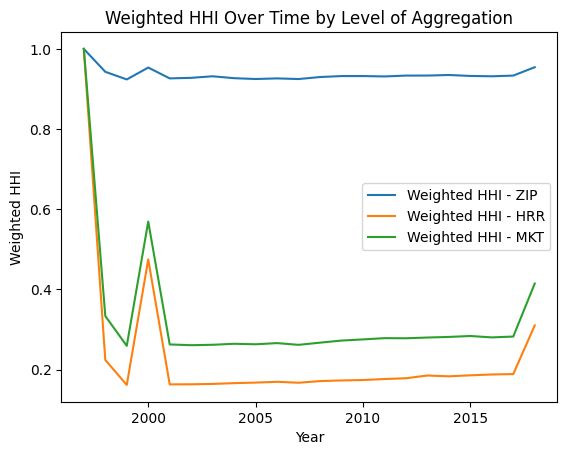

In [51]:
def calculate_weighted_hhi(df, market):
    hhi = (
        df.groupby([market, 'year'])
        .apply(lambda x: (
            (x['tot_discharges'] / x['tot_discharges'].sum()) ** 2
        ).sum(), include_groups=False)
        .rename('HHI')
        .reset_index()
    )

    sizes = (
        df.groupby([market, 'year'])['tot_discharges']
        .sum()
        .rename('market_discharges')
        .reset_index()
    )

    result = hhi.merge(sizes, on=[market, 'year'])

    return (
        result.assign(weighted_hhi=lambda x: x.HHI * x.market_discharges)
        .groupby('year')
        .apply(
            lambda x: x.weighted_hhi.sum() / x.market_discharges.sum(),
            include_groups=False
        )
    )

for market in ['zip', 'hrr', 'mkt']:
    weighted_hhi = calculate_weighted_hhi(hospital_panel, market)
    print(f"Weighted HHI for {market.upper()}:\n{weighted_hhi}\n")
    plt.plot(weighted_hhi.index, weighted_hhi.values, label=f'Weighted HHI - {market.upper()}')

plt.xlabel('Year')
plt.ylabel('Weighted HHI')
plt.title('Weighted HHI Over Time by Level of Aggregation')
plt.legend()
plt.show()


From the first part, just calculating a simple average gives a small market the same weight as a large market when calculating the HHI, so small markets raise the average HHI. Weighting by discharges changes the result because it gives larger markets more weighting over the HHI calculations.  Excluding single hospital markets ensures that single hospital markets does not raise the average HHI.
The plain average was leaving out the concentration experienced across the total hospital discharges that are influenced by the size of the market.


(3 points) A sanity check on the join. Market share’s denominator is total discharges in the correctly grouped market. Add a check that shares sum to 1 within each market-year, and explain what a careless join, one that mismatched hospitals to markets, would do to that check and to your HHI.



In [52]:
for market in ['zip', 'hrr', 'mkt']:
    share_sums = (
        hospital_panel
        .groupby([market, 'year'])['tot_discharges']
        .apply(lambda x: (x / x.sum()).sum())
    )

    print(
        f"{market}:",
        np.allclose(share_sums.values, 1.0)
    )

    assert np.allclose(share_sums.values, 1.0)

print(share_sums.head())
print("All share sums for zip codes are equal to 1.0:", np.allclose(share_sums.values, 1.0))
print("All share sums for HRRs are equal to 1.0:", np.allclose(share_sums.values, 1.0))
print("All share sums for communities are equal to 1.0:", np.allclose(share_sums.values, 1.0))

zip: True
hrr: True
mkt: True
mkt  year
1.0  1998    1.0
     1999    1.0
     2000    1.0
     2001    1.0
     2002    1.0
Name: tot_discharges, dtype: float64
All share sums for zip codes are equal to 1.0: True
All share sums for HRRs are equal to 1.0: True
All share sums for communities are equal to 1.0: True


A careless join that mismatch hospitals to markets would assign the hospitals to incorrect corresponding markets, causing certain hospitals to be duplicated and some hospitals to be omitted. Therefore, the market share and HHI will be inaccurate, and a join that incorrectly assigns hospitals but produce complete observations will still pass to sum to one check, so this check is necessary to do a sanity check on the join. 

(3 points) Maximum share instead of HHI. Recompute part (a) using the maximum market share 
 instead of HHI (average across markets, plot over time). Does your assessment of competitiveness change, and what does the contrast with HHI tell you?

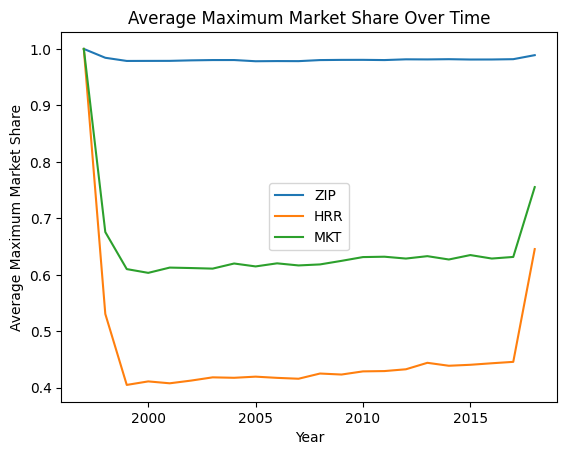

In [54]:
market_definitions = ['zip', 'hrr', 'mkt']

for market in market_definitions:
    max_share = (
        hospital_panel
        .groupby([market, 'year'])['tot_discharges']
        .apply(lambda x: x.max() / x.sum())
    )

    avg_max_share = max_share.groupby('year').mean()

    plt.plot(
        avg_max_share.index,
        avg_max_share.values,
        label=market.upper()
    )

plt.title('Average Maximum Market Share Over Time')
plt.xlabel('Year')
plt.ylabel('Average Maximum Market Share')
plt.legend()
plt.show()

After recomputing the average market share over time, I found out that the average maximum market share is lower than the HHI zip code but similar in value as the HHI at the community level. This is because HHI considers the distrubtion of shares across all hospitals, while maximum market share only considers the largest hospital. An average maximum share of 60% suggest the largest hospital has a big portion in the community market. Therefore, many markets have adominant hospital. This results changes my competitiveness assessment because I found out th at only considering the largest hospitals, the average maximum market share is about 60% across 2000-2015, therefore my assessment of competitiveness from HHI alone changes.

## Q2 — Prices and market structure (15 pts)


(3 points) The price variable. Compute the average hospital price in each year and plot it. Then look closely at the price variable itself. This price is not a sticker price. It is constructed from HCRIS as adjusted charges net of Medicare payments, divided by non-Medicare discharges, and it is in nominal dollars. Examine its distribution (its range and spread) and explain what this measure does and does not capture as a hospital “price,” and what those limitations mean for how you read the trend you plotted.



Average price in 1998: 5100.69
Average price in 1999: 5240.72
Average price in 2000: 5537.22
Average price in 2001: 5854.40
Average price in 2002: 6334.26
Average price in 2003: 6858.11
Average price in 2004: 7216.74
Average price in 2005: 7561.94
Average price in 2006: 7979.20
Average price in 2007: 8343.12
Average price in 2008: 8764.01
Average price in 2009: 9048.69
Average price in 2010: 9339.79
Average price in 2011: 9670.63
Average price in 2012: 9646.94
Average price in 2013: 9606.08
Average price in 2014: 10019.15
Average price in 2015: 10450.19
Average price in 2016: 10438.18
Average price in 2017: 10600.97
Average price in 2018: 11185.40
Average price in 1997: 4154.44


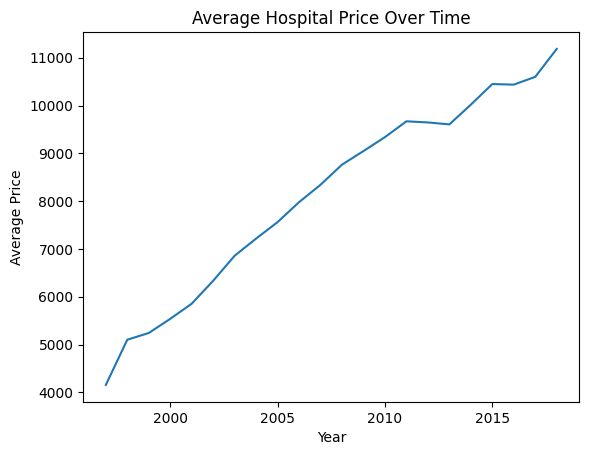

count    56942.000000
mean      8186.943401
std       5144.144169
min          1.953267
25%       4836.431671
50%       7152.183810
75%      10246.850503
max      97688.814928
Name: price, dtype: float64


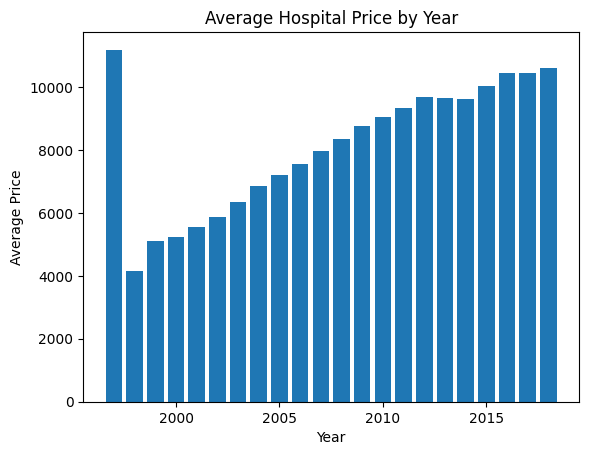

In [47]:
# Average hospital price in each year
for year in hospital_panel['year'].unique():
    avg_price = hospital_panel[hospital_panel['year'] == year]['price'].mean()
    print(f"Average price in {year}: {avg_price:.2f}")

avg_price = hospital_panel.groupby('year')['price'].mean()

plt.plot(avg_price.index, avg_price.values)
plt.title('Average Hospital Price Over Time')
plt.xlabel('Year')
plt.ylabel('Average Price')
plt.show()

print(hospital_panel['price'].describe())
plt.bar(hospital_panel['year'].unique(), hospital_panel.groupby('year')['price'].mean())
plt.title('Average Hospital Price by Year')
plt.xlabel('Year')
plt.ylabel('Average Price')
plt.show()

Although the average hospital price increasd from about $5000 in 1998 to $11, 000 in 2018. The average price is not a sticker price or what an individual pays, it is just a constructed hospital price based on adjusted charges net of Medicare prces and measured in nominal dollars. Therefore, the upward trend does not mean an increase in real prices. Another limitation is that  inflation should also be taken into account since prices also rose in general from 2000-2015 along with the average price increase. 

(3 points) Concentrated vs competitive markets. Identify market-years that are monopolies or duopolies (exactly one or two hospitals) and those that are “competitive” (at least four hospitals). Plot the count of each type over time.



structure  Monopoly  Duopoly  Competitive
year                                     
1997             13        0            0
1998            149       93          158
1999            146      103          248
2000            143       99          244
2001            148      102          243
2002            153       97          242
2003            147      101          245
2004            162       90          241
2005            151       91          241
2006            154       96          240
2007            150      104          240
2008            150      105          238
2009            154      105          236
2010            160      109          235
2011            157      100          229
2012            153      108          235
2013            157      105          230
2014            149      108          233
2015            155      105          236
2016            144      110          235
2017            147      113          232
2018            161       75      

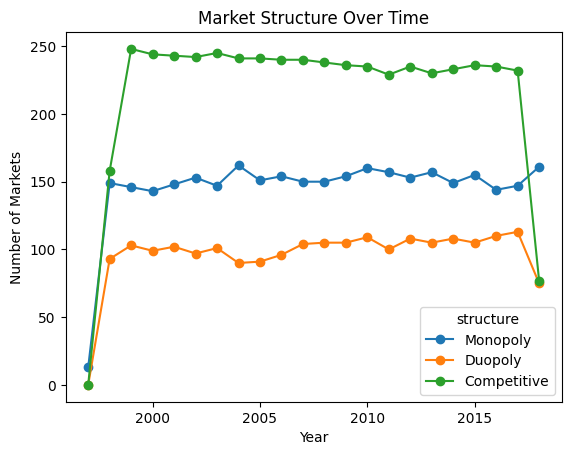

In [49]:
market_counts = (
    hospital_panel.groupby(['mkt', 'year'])
    .size()
    .reset_index(name='hospital_count')
)

market_counts['structure'] = np.select(
    [
        market_counts['hospital_count'] == 1,
        market_counts['hospital_count'] == 2,
        market_counts['hospital_count'] >= 4
    ],
    ['Monopoly', 'Duopoly', 'Competitive'],
    default='Other'
)

counts_over_time = (
    market_counts.groupby(['year', 'structure'])
    .size()
    .unstack(fill_value=0)
)

counts_over_time[['Monopoly', 'Duopoly', 'Competitive']].plot(
    marker='o'
)

print(counts_over_time[['Monopoly', 'Duopoly', 'Competitive']])

plt.title('Market Structure Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Markets')
plt.show()

(3 points) Price by market structure. Compute the average price in each year within the monopoly/duopoly group and within the competitive group. Show the comparison. Does concentration appear to correlate with price?



market_structure,Competitive,Monopoly/Duopoly
year,,
1997,NaN,4433.057276
1998,5128.707536,4901.087016
1999,5286.564469,4671.812025
2000,5623.713504,5090.899235
2001,5904.830646,5302.877515
2002,6355.361656,5817.387110
2003,6901.181099,6402.127507
2004,7223.317495,6920.812181
2005,7604.913573,7220.609929


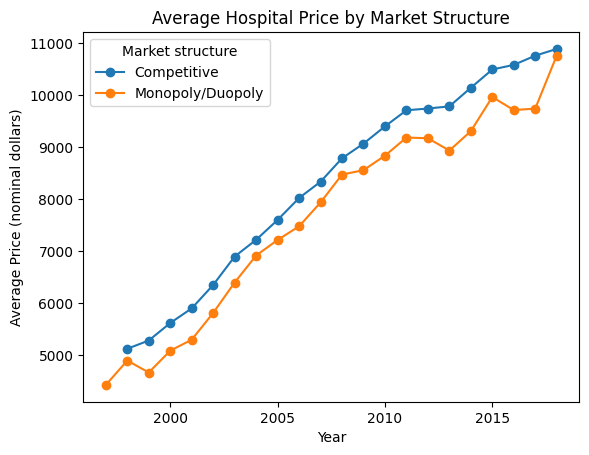

In [9]:
# Count hospitals in each community market-year and classify market structure
market_counts = (
    hospital_panel.groupby(['mkt', 'year'])
    .size()
    .rename('hospital_count')
    .reset_index()
)

price_data = hospital_panel.merge(market_counts, on=['mkt', 'year'])
price_data['market_structure'] = np.select(
    [
        price_data['hospital_count'].isin([1, 2]),
        price_data['hospital_count'] >= 4
    ],
    ['Monopoly/Duopoly', 'Competitive'],
    default='Other'
)

# Average hospital price by year and market structure
price_comparison = (
    price_data[price_data['market_structure'] != 'Other']
    .groupby(['year', 'market_structure'])['price']
    .mean()
    .unstack()
)

display(price_comparison)

price_comparison.plot(marker='o')
plt.title('Average Hospital Price by Market Structure')
plt.xlabel('Year')
plt.ylabel('Average Price (nominal dollars)')
plt.legend(title='Market structure')
plt.show()

Competitive markets have higher average prices than monopoly from 1998 to 2018. Therefore, concentration does not show a positive correlation or relationship between concenration and hospital prices because there are other factors like market size and rurality that influence prices.  

(3 points) The market-size confound. Concentrated markets differ systematically from competitive ones, tending to be smaller and more rural. Repeat part (c) after limiting to markets with between 10,000 and 50,000 total discharges per year. Explain what changes and why market size confounds the raw price-concentration relationship.



market_structure,Competitive,Monopoly/Duopoly
year,,
1998,4811.533724,5598.048534
1999,4788.386144,4983.394928
2000,5156.240608,5283.964159
2001,5242.862228,5485.869628
2002,5738.973078,6064.778830
2003,6249.138568,6506.761630
2004,6518.685076,7213.675142
2005,7234.048913,7596.062933
2006,7260.145432,7722.947701


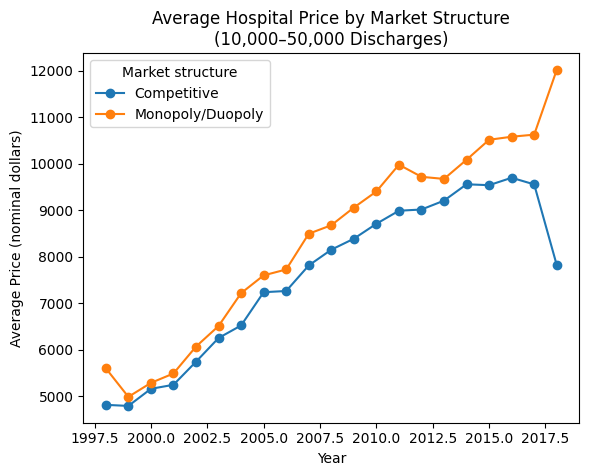

In [ ]:
market_sizes = (
    hospital_panel.groupby(['mkt', 'year'])['tot_discharges']
    .sum()
    .rename('market_discharges')
    .reset_index()
)

size_matched = price_data.merge(market_sizes, on=['mkt', 'year'])
size_matched = size_matched[
    size_matched['market_discharges'].between(10_000, 50_000)
]

matched_comparison = (
    size_matched[size_matched['market_structure'] != 'Other']
    .groupby(['year', 'market_structure'])['price']
    .mean()
    .unstack()
)

display(matched_comparison)

matched_comparison.plot(marker='o')
plt.title('Average Hospital Price by Market Structure\n(10,000–50,000 Discharges)')
plt.xlabel('Year')
plt.ylabel('Average Price (nominal dollars)')
plt.legend(title='Market structure')
plt.show()

After restricting the sample to markets with 10000-50000 discharges, monopoly and duopoly markets have higher average prices. Therefore, market size is an important confounding factor since concentrated markets are smaller and more rural that infleunce market sizes. Restricting by market size makes the relationship more prominent with concentration and average prices.

(3 points) Is it causal? State your conclusion. Is the price-concentration correlation you found causal evidence that concentration raises prices, and what would you need to make a causal claim?



It appears that hospitals in monopoly or duopoly markets tend to have higher average hospital prices after restricting sample to markets with 10,000-50,000 discharges. However, this does not establish the casual relationship that concentration causes higher prices, because there are omitted variable bias like hospital quality, patient characteristics, and local demand that will affect the relationship between concentration and prices, and market size restrction address only one confounder.  

To establsih a casual relationship between concentration and prices, I would need to look at if there is an exogenous change in market concentration like a merger of two hospitals, and a difference and difference comparison for post treatment vs. pre-treatment prices.

